# Step 6: Risk-profile clustering

**Client:** NASA/JPL Planetary Defense Coordination Office (PDCO)

### What we are looking for

Steps 4 and 5 give a score **per object**. But the PDCO organizes its work in **observation campaigns**: the same telescope, the same strategy, for a set of similar objects. The question of this step:

> **Does the catalogue naturally split into a few risk profiles, each calling for a different follow-up strategy?**

### What we do

| | |
|---|---|
| **Method** | K-Means (**unsupervised** learning: no target) |
| **Objects** | The whole catalogue (41,281 objects, minus those without a MOID) |
| **Variables** | Size (diameter from step 4), proximity (MOID), inclination, eccentricity |
| **Choice of K** | Elbow method and silhouette score |
| **Afterwards** | Each group is described with information **not used** to form it: share of PHAs, step 5 probability, close approaches 2015–2035, orbital family |

### What we want to avoid

In step 2 we saw that the Apollo, Amor, Aten and Atira families are **defined by thresholds on the orbit**. A clustering that recovered them would learn nothing. We will therefore check that our groups **mix** these families.

This notebook uses the outputs of steps 4 and 5: run notebooks 03, 04 and 05 first.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def find_project_dir() -> Path:
    for base in [Path.cwd(), *Path.cwd().parents]:
        for candidate in (base, base / "nasa-project"):
            if (candidate / "data" / "raw").is_dir():
                return candidate
    raise FileNotFoundError("Folder nasa-project/data/raw not found.")

PROJECT_DIR = find_project_dir()
RAW_DIR = PROJECT_DIR / "data" / "raw"
DIAM_FILE = PROJECT_DIR / "data" / "processed" / "04_diameter" / "catalogue_diameters.csv"
SCORE_FILE = PROJECT_DIR / "data" / "processed" / "05_classification" / "catalogue_scores.csv"
PROCESSED_DIR = PROJECT_DIR / "data" / "processed" / "06_clustering"
REPORT_DIR = PROJECT_DIR / "reports" / "06_clustering"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)
for f, step in [(DIAM_FILE, "04_diameter_regression"), (SCORE_FILE, "05_classification")]:
    if not f.exists():
        raise FileNotFoundError(f"Run {step}.ipynb first.")

RANDOM_STATE = 42
LD_AU = 0.00257   # 1 lunar distance in AU

# Ordered categorical palette (one cluster = one color, always the same)
CLUSTER_COLORS = ["#2878B5", "#E07A2D", "#3A8F5C", "#8E5BAA", "#C0392B", "#8C6D31"]
GREY, RED = "#8C8C8C", "#C0392B"
LABEL_BOX = dict(facecolor="white", edgecolor="none", alpha=0.85, pad=1.5)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.25})

def save(fig, name):
    fig.savefig(REPORT_DIR / f"{name}.png", dpi=160, bbox_inches="tight")

def fmt(n):
    return f"{n:,.0f}"

## 1. Assembling the data

In [2]:
asteroids = pd.read_csv(sorted(RAW_DIR.glob("near_earth_asteroids_2025*.csv"))[0], low_memory=False)
approaches = pd.read_csv(sorted(RAW_DIR.glob("asteroid_close_approaches_2015_2035*.csv"))[0], low_memory=False)
diameters = pd.read_csv(DIAM_FILE)
scores = pd.read_csv(SCORE_FILE)

# Close approaches 2015–2035, summarized per object (only used to DESCRIBE the clusters)
close = (approaches.groupby("designation")
         .agg(n_approaches=("dist_lunar", "size"), min_distance_LD=("dist_lunar", "min"),
              max_velocity_kms=("velocity_km_s", "max"))
         .reset_index().rename(columns={"designation": "pdes"}))

data = (asteroids[["pdes", "full_name", "pha", "class", "moid_au", "i", "e", "a", "q", "ad", "H"]]
        .merge(diameters[["pdes", "diameter_km", "diameter_km_high", "diameter_source", "out_of_domain"]], on="pdes", how="left")
        .merge(scores[["pdes", "pha_proba", "flagged"]], on="pdes", how="left")
        .merge(close, on="pdes", how="left"))
data["n_approaches"] = data["n_approaches"].fillna(0).astype(int)

missing = data["moid_au"].isna() | data["diameter_km"].isna()
print(f"Objects without MOID or diameter, excluded from clustering: {missing.sum()} ({missing.mean():.1%})")
data = data[~missing].reset_index(drop=True)
print(f"Objects clustered: {fmt(len(data))}")

Objects without MOID or diameter, excluded from clustering: 131 (0.3%)
Objects clustered: 41,150


## 2. Choice of variables

Four variables, each answering a different question for the PDCO:

| Variable | Question | Transformation |
|---|---|---|
| **Diameter** (step 4) | How severe would an impact be? | log₁₀: sizes range from 1 m to 30 km |
| **MOID** | Can the orbit come close to Earth? | log₁₀: most values are close to 0 |
| **Inclination i** | Does the object stay close to the plane of Earth's orbit? A high inclination changes the observing windows and increases the encounter velocity. | none |
| **Eccentricity e** | Is the orbit elongated? A high eccentricity means fast and rare passages. | none |

`a`, `q` and `ad` are left out: they are redundant with e and the MOID (step 2).

K-Means measures distances: all variables are **standardized** so they carry the same weight. There is no target and no generalization to evaluate, so no train/test split here. `pha` is **not** used for clustering, only to describe the groups afterwards.

In [3]:
features = pd.DataFrame({
    "log10_diameter": np.log10(data["diameter_km"]),
    "log10_moid": np.log10(data["moid_au"] + 1e-4),   # +1e-4 AU avoids log(0)
    "inclination": data["i"],
    "eccentricity": data["e"],
})
X = StandardScaler().fit_transform(features)
features.describe().T[["mean", "std", "min", "50%", "max"]]

,mean,std,min,50%,max
log10_diameter,-1.130,0.611,-3.292,-1.206,1.576
log10_moid,-1.491,0.730,-3.998,-1.373,-0.150
inclination,11.840,10.550,0.010,8.400,165.600
eccentricity,0.434,0.177,0.003,0.448,0.996


## 2b. Justifying the variables: correlations and PCA

The previous choice relies on business and physical arguments. We now check it with two statistical tools:

1. **The correlation matrix** of the candidate variables: two highly correlated variables carry the same information and would double its weight in K-Means.
2. **Principal component analysis (PCA)** on the 4 selected variables: it tells whether they could be summarized in fewer dimensions without significant loss.

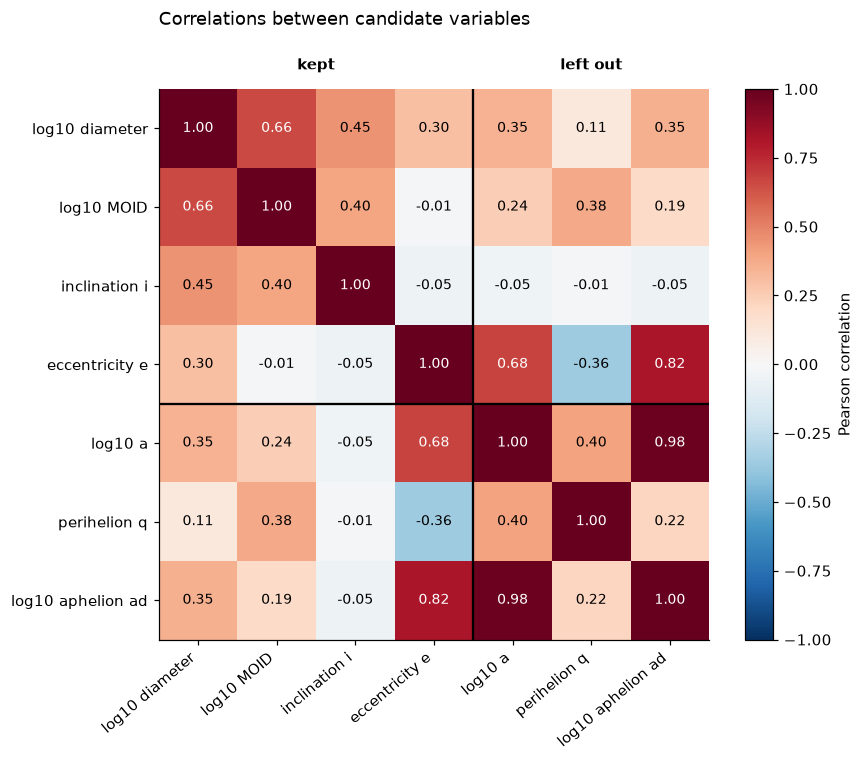

In [4]:
candidates = pd.DataFrame({
    "log10 diameter": np.log10(data["diameter_km"]),
    "log10 MOID": np.log10(data["moid_au"] + 1e-4),
    "inclination i": data["i"],
    "eccentricity e": data["e"],
    "log10 a": np.log10(data["a"]),
    "perihelion q": data["q"],
    "log10 aphelion ad": np.log10(data["ad"]),
})
corr = candidates.corr()
corr.round(2).to_csv(REPORT_DIR / "variable_correlations.csv")

fig, ax = plt.subplots(figsize=(8.5, 6.5))
im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=40, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for r in range(len(corr)):
    for c in range(len(corr)):
        v = corr.values[r, c]
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=9,
                color="white" if abs(v) > 0.6 else "black")
ax.axhline(3.5, color="black", lw=1.5); ax.axvline(3.5, color="black", lw=1.5)
ax.text(1.5, -0.75, "kept", ha="center", fontsize=10, fontweight="bold")
ax.text(5, -0.75, "left out", ha="center", fontsize=10, fontweight="bold")
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.04, label="Pearson correlation")
ax.set_title("Correlations between candidate variables", loc="left", pad=42)
save(fig, "variable_correlations")
plt.show()

**Reading:**

- **`a` and `ad` are almost identical** (r ≈ 0.98) and `ad` closely follows the eccentricity (r ≈ 0.8). Keeping them alongside `e` would count the same information two or three times.
- **`q`** is a combination of `a` and `e`, linked to the MOID: it brings no independent information. It is also used to define the orbital families, which we do not want to rediscover.
- **Among the 4 selected variables**, the only strong correlation is between **size and MOID** (r ≈ 0.66). It comes from **detection bias**: a small object is only discovered if it passes very close to Earth. We keep both, since size and proximity are two distinct dimensions of risk, but this correlation will shape the clusters.

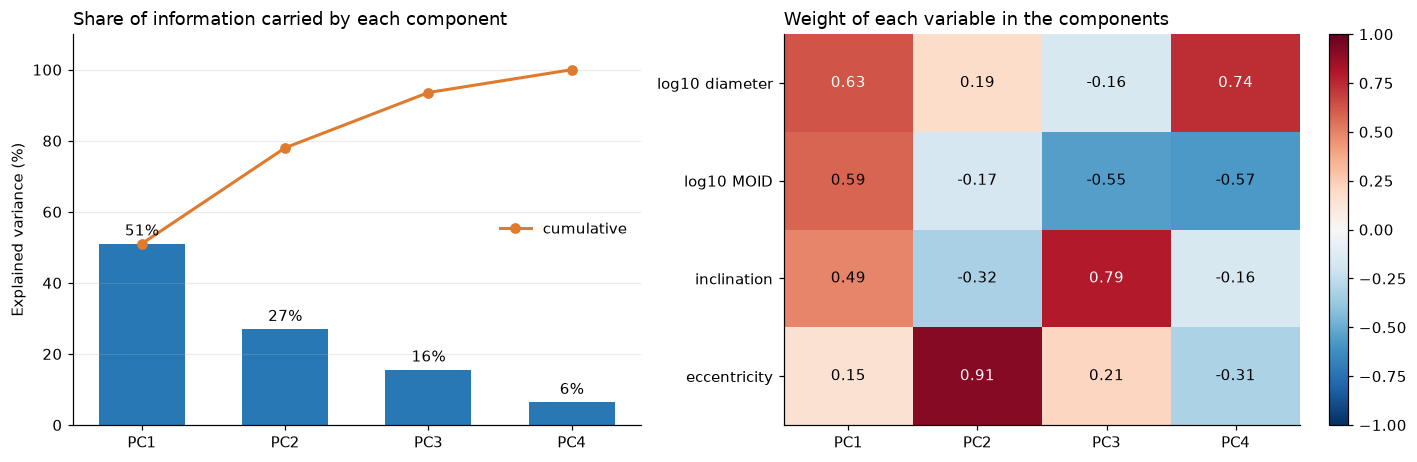

,explained variance,cumulative variance
PC1,0.510,0.510
PC2,0.270,0.780
PC3,0.156,0.936
PC4,0.064,1.000


In [5]:
pca = PCA().fit(X)
explained = pd.DataFrame({
    "explained variance": pca.explained_variance_ratio_,
    "cumulative variance": np.cumsum(pca.explained_variance_ratio_),
}, index=[f"PC{k + 1}" for k in range(X.shape[1])])
loadings = pd.DataFrame(pca.components_.T, index=features.columns,
                        columns=[f"PC{k + 1}" for k in range(X.shape[1])])
explained.to_csv(REPORT_DIR / "pca_variance.csv")
loadings.to_csv(REPORT_DIR / "pca_loadings.csv")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
ax = axes[0]
bars = ax.bar(explained.index, explained["explained variance"] * 100, color=CLUSTER_COLORS[0], width=0.6)
ax.bar_label(bars, labels=[f"{v:.0%}" for v in explained["explained variance"]], padding=3)
ax.plot(explained.index, explained["cumulative variance"] * 100, marker="o", color=CLUSTER_COLORS[1], lw=2, label="cumulative")
ax.set_ylim(0, 110)
ax.set_ylabel("Explained variance (%)")
ax.set_title("Share of information carried by each component", loc="left")
ax.legend(frameon=False, loc="center right")
ax.grid(axis="x", visible=False)

ax = axes[1]
im = ax.imshow(loadings.values, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
ax.set_xticks(range(loadings.shape[1]), loadings.columns)
ax.set_yticks(range(len(loadings)), ["log10 diameter", "log10 MOID", "inclination", "eccentricity"])
for r in range(loadings.shape[0]):
    for c in range(loadings.shape[1]):
        v = loadings.values[r, c]
        ax.text(c, r, f"{v:.2f}", ha="center", va="center", fontsize=10, color="white" if abs(v) > 0.6 else "black")
ax.grid(False)
ax.set_title("Weight of each variable in the components", loc="left")
fig.colorbar(im, ax=ax, fraction=0.04)
fig.tight_layout()
save(fig, "pca_variance_loadings")
plt.show()
explained.round(3)

**Reading:**

- **PC1 (about half of the information)** combines size, MOID and inclination: it contrasts **small, close, low-inclination** objects with **large, distant, inclined** ones. It is the detection-bias axis.
- **PC2** is almost entirely the **eccentricity**, which varies independently of the others.
- **PC3 and PC4** still carry about 20% of the information together.

**Decision:** 3 components are needed to keep more than 90% of the information. Replacing the 4 variables with 2 components would lose more than 20% of the information, and the clusters would be harder to describe to the PDCO ("high PC1" says less than "large objects"). **We therefore cluster on the 4 original variables**, and PCA is used to visualize the result (section 5).

## 3. Choosing the number of groups K

- **Elbow method**: inertia (dispersion within groups) always decreases as K increases. We look for the point where the decrease slows down.
- **Silhouette score**: for each object, compares the distance to its own group with the distance to the neighboring group. It ranges from −1 to 1: close to 1, groups are well separated; close to 0, they overlap.

The silhouette is computed on a sample of 10,000 objects to stay fast.

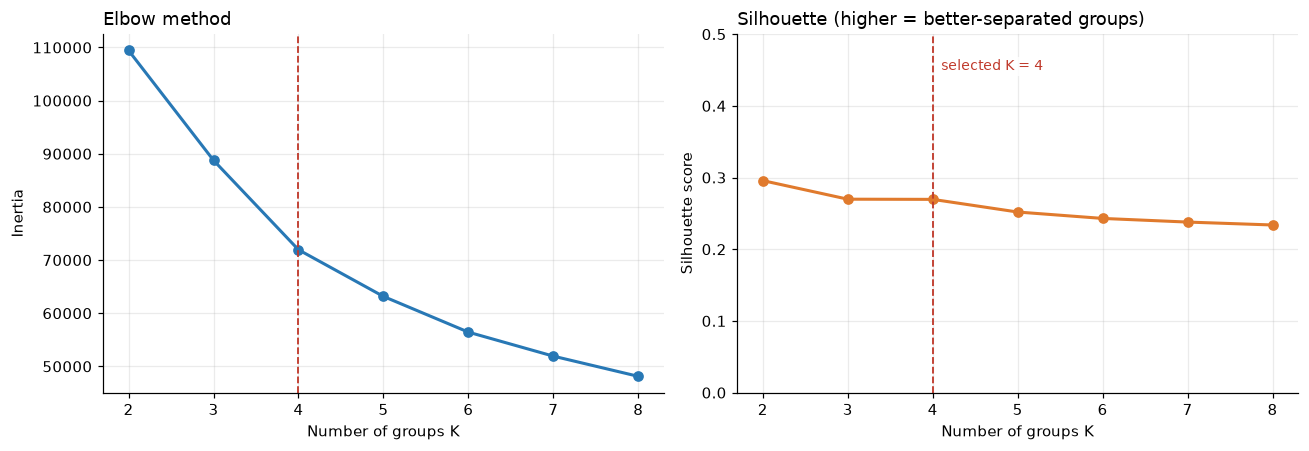

,K,inertia,silhouette
0,2,"109,435.861",0.296
1,3,"88,771.134",0.270
2,4,"71,941.871",0.270
3,5,"63,160.143",0.252
4,6,"56,442.422",0.243
5,7,"51,927.014",0.238
6,8,"48,125.510",0.234


In [6]:
rng = np.random.default_rng(RANDOM_STATE)
sample = rng.choice(len(X), size=min(10_000, len(X)), replace=False)

ks = range(2, 9)
inertia, silhouette = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X[sample], km.labels_[sample]))

k_table = pd.DataFrame({"K": list(ks), "inertia": inertia, "silhouette": silhouette})
k_table.to_csv(REPORT_DIR / "k_selection.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].plot(list(ks), inertia, marker="o", color=CLUSTER_COLORS[0], lw=2)
axes[0].set_xlabel("Number of groups K"); axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow method", loc="left")
axes[1].plot(list(ks), silhouette, marker="o", color=CLUSTER_COLORS[1], lw=2)
axes[1].set_xlabel("Number of groups K"); axes[1].set_ylabel("Silhouette score")
axes[1].set_ylim(0, 0.5)
axes[1].set_title("Silhouette (higher = better-separated groups)", loc="left")
K = 4
for ax in axes:
    ax.axvline(K, color=RED, ls="--", lw=1.2)
axes[1].text(K + 0.1, 0.45, f"selected K = {K}", color=RED, fontsize=9, bbox=LABEL_BOX)
fig.tight_layout()
save(fig, "k_selection")
plt.show()
k_table.round(3)

**Reading:**

- The silhouette is highest for K = 2, but two groups ("small" vs "large") are not enough to define different campaigns.
- Between K = 3 and K = 4 the silhouette stays stable, then decreases steadily. The elbow is not sharp.
- **We select K = 4**: the largest number of groups before the separation degrades.

**Limitation to report:** a silhouette of about 0.27 indicates **overlapping** groups. Near-Earth objects form a continuum, not well-separated families. The clusters are therefore **useful partitions for organizing the work**, not natural categories.

## 4. Group stability

In [7]:
reference = KMeans(n_clusters=K, n_init=10, random_state=RANDOM_STATE).fit(X)
labels_ref = reference.labels_
ari = [adjusted_rand_score(labels_ref, KMeans(n_clusters=K, n_init=10, random_state=s).fit_predict(X))
       for s in range(1, 6)]
print(f"Agreement between 5 reruns with different initializations (ARI): "
      f"mean {np.mean(ari):.3f}, minimum {np.min(ari):.3f}  (1 = identical groups)")

Agreement between 5 reruns with different initializations (ARI): mean 0.988, minimum 0.965  (1 = identical groups)


An ARI close to 1 means K-Means finds **the same groups** whatever its random initialization. The groups overlap, but they are **reproducible**.

## 5. Profile of each group

In [8]:
# Renumber by increasing median diameter, for stable and readable labels
order = pd.Series(np.log10(data["diameter_km"])).groupby(labels_ref).median().sort_values().index
relabel = {old: new for new, old in enumerate(order)}
data["cluster"] = pd.Series(labels_ref).map(relabel).to_numpy()

total_pha = data["pha"].sum()
profile = data.groupby("cluster").agg(
    objects=("pdes", "size"),
    median_diameter_m=("diameter_km", lambda s: s.median() * 1000),
    median_moid_AU=("moid_au", "median"),
    median_inclination=("i", "median"),
    median_eccentricity=("e", "median"),
    pha_share=("pha", "mean"),
    n_pha=("pha", "sum"),
    mean_pha_proba=("pha_proba", "mean"),
    share_flagged_step5=("flagged", "mean"),
    share_approach_below_5LD=("min_distance_LD", lambda s: (s < 5).sum() / len(s)),
    share_out_of_domain_diameter=("out_of_domain", "mean"),
)
profile["share_of_all_phas"] = profile["n_pha"] / total_pha
profile.to_csv(REPORT_DIR / "cluster_profiles.csv")
profile.round(3).T

cluster,0,1,2,3
objects,"11,002.000","10,845.000","13,288.000","6,015.000"
median_diameter_m,18.582,41.898,162.880,383.364
median_moid_AU,0.005,0.046,0.078,0.170
median_inclination,4.030,11.290,7.485,28.470
median_eccentricity,0.476,0.245,0.541,0.461
pha_share,0.010,0.022,0.122,0.094
n_pha,107.000,241.000,"1,625.000",566.000
mean_pha_proba,0.056,0.075,0.266,0.314
share_flagged_step5,0.168,0.181,0.457,0.577
share_approach_below_5LD,0.436,0.036,0.003,0.004


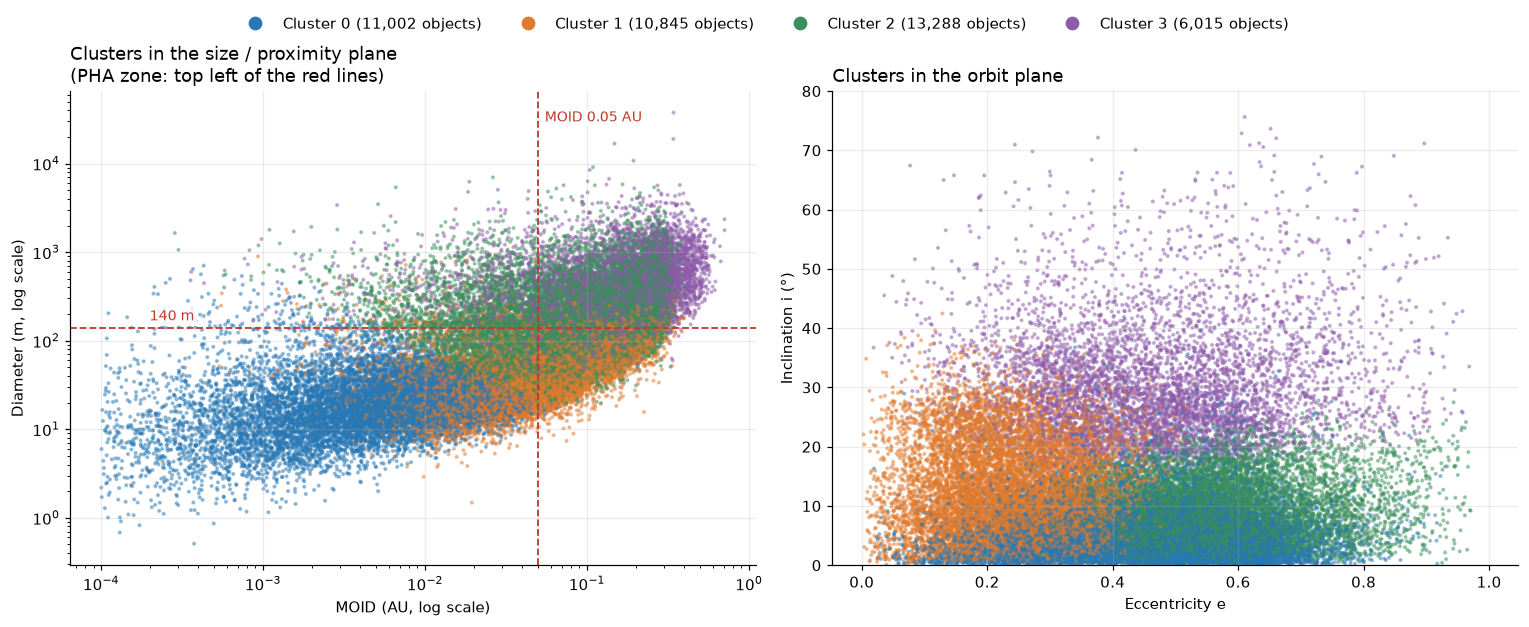

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
colors = ListedColormap(CLUSTER_COLORS[:K])

ax = axes[0]
ax.scatter(data["moid_au"] + 1e-4, data["diameter_km"] * 1000, c=data["cluster"], cmap=colors,
           s=3, alpha=0.4, rasterized=True, vmin=-0.5, vmax=K - 0.5)
ax.set_xscale("log"); ax.set_yscale("log")
ax.axvline(0.05, color=RED, ls="--", lw=1.2)
ax.axhline(140, color=RED, ls="--", lw=1.2)
ax.text(0.055, 3e4, "MOID 0.05 AU", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.text(2e-4, 170, "140 m", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("MOID (AU, log scale)")
ax.set_ylabel("Diameter (m, log scale)")
ax.set_title("Clusters in the size / proximity plane\n(PHA zone: top left of the red lines)", loc="left")

ax = axes[1]
ax.scatter(data["e"], data["i"], c=data["cluster"], cmap=colors, s=3, alpha=0.4,
           rasterized=True, vmin=-0.5, vmax=K - 0.5)
ax.set_xlabel("Eccentricity e")
ax.set_ylabel("Inclination i (°)")
ax.set_ylim(0, 80)
ax.set_title("Clusters in the orbit plane", loc="left")

handles = [plt.Line2D([], [], marker="o", ls="", color=CLUSTER_COLORS[c], markersize=8,
                      label=f"Cluster {c} ({fmt(profile.loc[c, 'objects'])} objects)") for c in range(K)]
fig.legend(handles=handles, loc="upper center", ncol=K, frameon=False, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
save(fig, "cluster_projections")
plt.show()

### Overview: the clusters in the PCA plane

All objects are projected on the first two components (about 78% of the information), each point colored by its cluster. The arrows show the direction of each original variable in this plane.

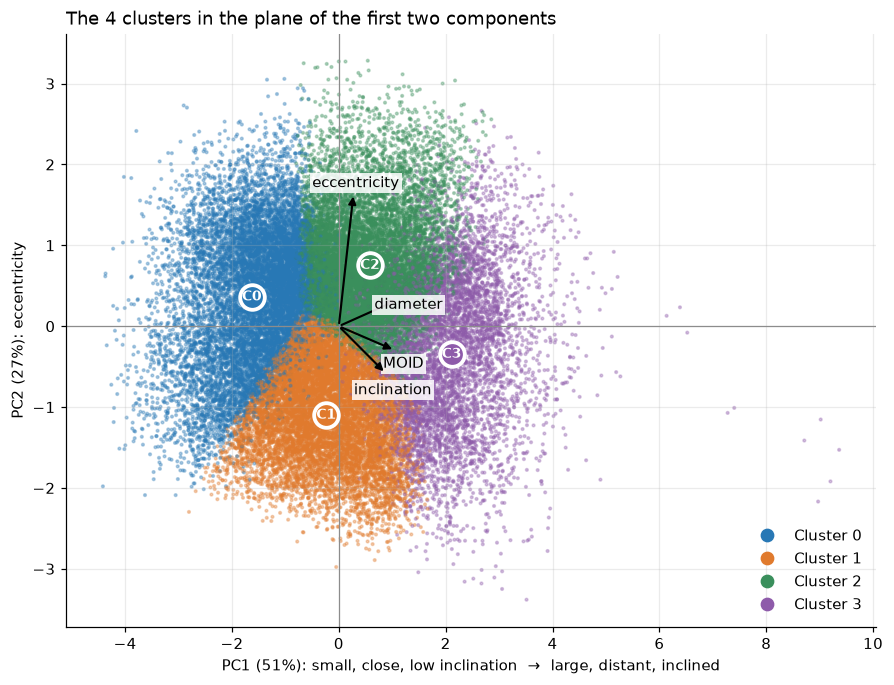

In [10]:
coords = pca.transform(X)[:, :2]
fig, ax = plt.subplots(figsize=(9.5, 7))
ax.scatter(coords[:, 0], coords[:, 1], c=data["cluster"], cmap=ListedColormap(CLUSTER_COLORS[:K]),
           s=3, alpha=0.35, rasterized=True, vmin=-0.5, vmax=K - 0.5)
centers = pd.DataFrame(coords).groupby(data["cluster"].to_numpy()).mean()
for c, (x0, y0) in centers.iterrows():
    ax.scatter(x0, y0, s=260, color=CLUSTER_COLORS[c], edgecolor="white", linewidth=2.5, zorder=5)
    ax.text(x0, y0, f"C{c}", ha="center", va="center", color="white", fontsize=9, fontweight="bold", zorder=6)
scale = 1.8
names = ["diameter", "MOID", "inclination", "eccentricity"]
for name, (lx, ly) in zip(names, pca.components_[:2].T):
    ax.annotate("", xy=(lx * scale, ly * scale), xytext=(0, 0),
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.4))
    ax.text(lx * scale * 1.15, ly * scale * 1.15 - 0.12, name, fontsize=10, ha="center", va="center", bbox=LABEL_BOX)
ax.axhline(0, color=GREY, lw=0.8); ax.axvline(0, color=GREY, lw=0.8)
ev = pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({ev[0]:.0%}): small, close, low inclination  →  large, distant, inclined")
ax.set_ylabel(f"PC2 ({ev[1]:.0%}): eccentricity")
ax.set_title("The 4 clusters in the plane of the first two components", loc="left")
handles = [plt.Line2D([], [], marker="o", ls="", color=CLUSTER_COLORS[c], markersize=8, label=f"Cluster {c}") for c in range(K)]
ax.legend(handles=handles, frameon=False, loc="lower right")
save(fig, "pca_projection_clusters")
plt.show()

**Reading:** the clusters are ordered along **PC1**, from cluster 0 (small close approachers, on the left) to cluster 3 (large inclined objects, on the right). **PC2** then separates low-eccentricity orbits (cluster 1, bottom) from highly elongated ones (clusters 0 and 2, top). The clouds touch, which visually confirms the moderate silhouette: they are **regions of a continuum**, not isolated groups.

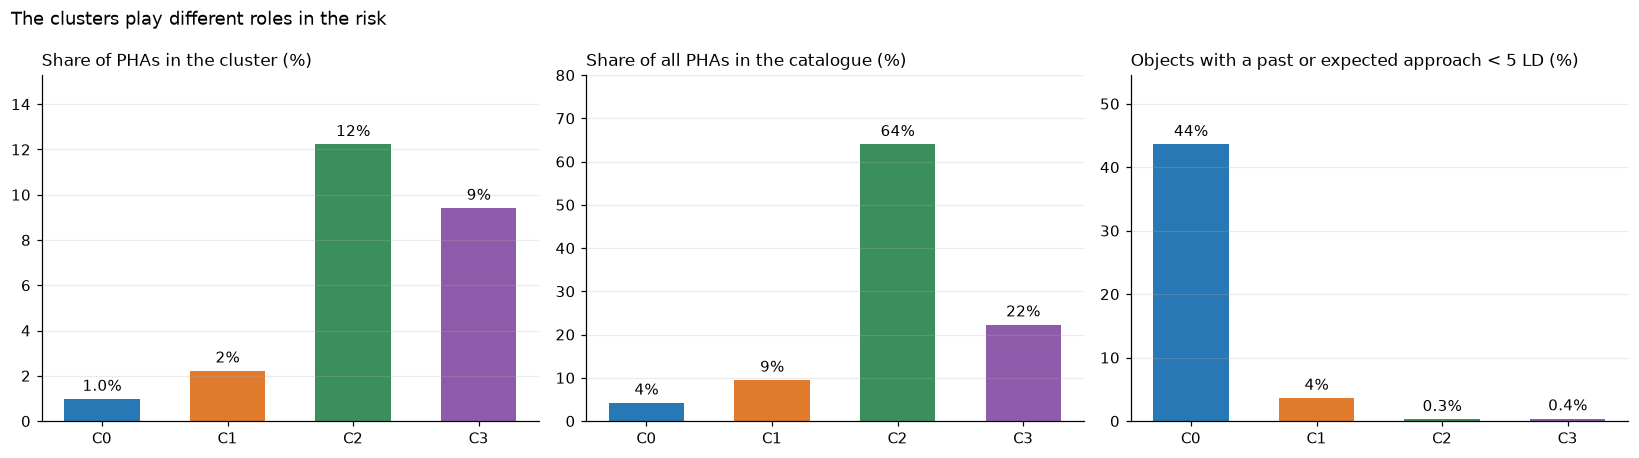

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
metrics = [
    ("pha_share", "Share of PHAs in the cluster (%)", 100),
    ("share_of_all_phas", "Share of all PHAs in the catalogue (%)", 100),
    ("share_approach_below_5LD", "Objects with a past or expected approach < 5 LD (%)", 100),
]
for ax, (col, title, scale) in zip(axes, metrics):
    vals = profile[col] * scale
    bars = ax.bar([f"C{c}" for c in profile.index], vals, color=CLUSTER_COLORS[:K], width=0.6)
    ax.bar_label(bars, labels=[f"{v:.0f}%" if v >= 1 else f"{v:.1f}%" for v in vals], padding=3)
    ax.set_ylim(0, vals.max() * 1.25)
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="x", visible=False)
fig.suptitle("The clusters play different roles in the risk", x=0.01, ha="left")
fig.tight_layout()
save(fig, "cluster_risk")
plt.show()

## 6. Do the clusters recover the orbital families?

If each cluster matched a family (Apollo, Amor, Aten, Atira), the clustering would bring nothing new.

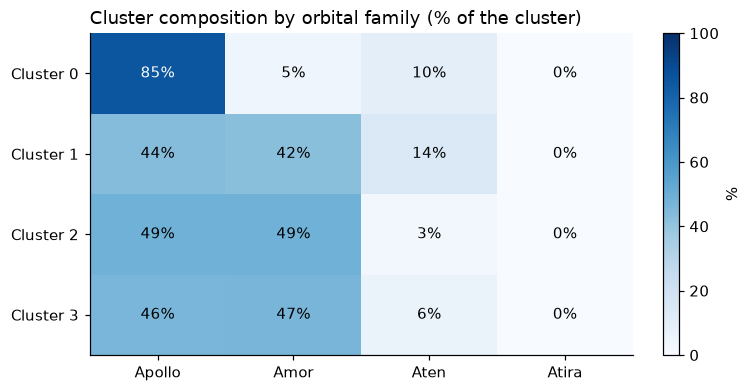

Cluster / family agreement (ARI): 0.077  (0 = no link)


In [12]:
family_names = {"APO": "Apollo", "AMO": "Amor", "ATE": "Aten", "IEO": "Atira"}
cross = pd.crosstab(data["cluster"], data["class"].map(family_names), normalize="index") * 100
cross = cross[[c for c in ["Apollo", "Amor", "Aten", "Atira"] if c in cross.columns]]
cross.to_csv(REPORT_DIR / "clusters_vs_families.csv")

fig, ax = plt.subplots(figsize=(7, 3.8))
im = ax.imshow(cross.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(cross.shape[1]), cross.columns)
ax.set_yticks(range(K), [f"Cluster {c}" for c in cross.index])
for r in range(cross.shape[0]):
    for c in range(cross.shape[1]):
        v = cross.values[r, c]
        ax.text(c, r, f"{v:.0f}%", ha="center", va="center", color="white" if v > 60 else "black", fontsize=10)
ax.grid(False)
ax.set_title("Cluster composition by orbital family (% of the cluster)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.04, label="%")
save(fig, "clusters_vs_families")
plt.show()
print(f"Cluster / family agreement (ARI): {adjusted_rand_score(data['class'], data['cluster']):.3f}  (0 = no link)")

**Reading:**

- **Three clusters out of four mix Apollo and Amor in almost equal parts**, and the ARI between clusters and families is close to 0. The clustering does not rediscover the official classification: it splits the catalogue along **other criteria**, related to risk (size, proximity, inclination) rather than orbit geometry alone.
- **Cluster 0 is 85% Apollo.** This is consistent: its objects skim Earth's orbit (very low MOID), which requires an orbit that crosses it, the very definition of Apollos. Even there, 15% of the objects come from other families.

## 7. Quality of each group: detailed silhouette

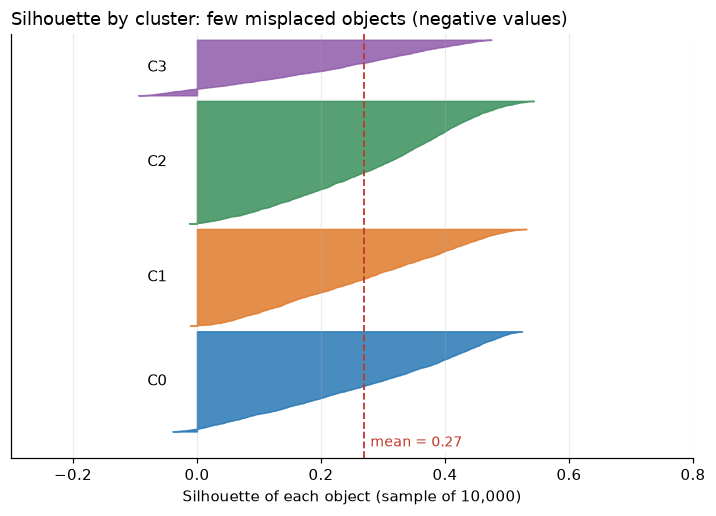

,mean silhouette
0,0.276
1,0.270
2,0.289
3,0.212


In [13]:
sil = silhouette_samples(X[sample], data["cluster"].to_numpy()[sample])
fig, ax = plt.subplots(figsize=(8, 5))
y0 = 0
for c in range(K):
    vals = np.sort(sil[data["cluster"].to_numpy()[sample] == c])
    ax.fill_betweenx(np.arange(y0, y0 + len(vals)), 0, vals, color=CLUSTER_COLORS[c], alpha=0.85)
    ax.text(-0.08, y0 + len(vals) / 2, f"C{c}", va="center", fontsize=10)
    y0 += len(vals) + 150
ax.axvline(sil.mean(), color=RED, ls="--", lw=1.2)
ax.text(sil.mean() + 0.01, -400, f"mean = {sil.mean():.2f}", color=RED, fontsize=9, bbox=LABEL_BOX)
ax.set_xlabel("Silhouette of each object (sample of 10,000)")
ax.set_yticks([])
ax.set_ylim(-700, y0)
ax.set_xlim(-0.3, 0.8)
ax.set_title("Silhouette by cluster: few misplaced objects (negative values)", loc="left")
save(fig, "silhouette_by_cluster")
plt.show()
pd.Series(sil).groupby(data["cluster"].to_numpy()[sample]).mean().rename("mean silhouette").to_frame()

## 8. From clusters to observation campaigns

The table below translates each cluster into a **follow-up strategy**. The names and recommendations are derived from the profile figures (section 5); review them if you rerun the notebook on other data.

In [14]:
def describe(row):
    big = row["median_diameter_m"] >= 140
    close = row["median_moid_AU"] <= 0.02
    inclined = row["median_inclination"] >= 20
    if not big and close:
        return ("Small close approachers",
                "Mostly detected during very close passes. Rapid follow-up right after discovery, then passive surveillance.")
    if not big:
        return ("Small objects at moderate distance",
                "Low individual risk. Passive surveillance by automated surveys.")
    if inclined:
        return ("Large highly inclined objects",
                "Large but distant on average. Hard-to-reach orbits: regular astrometric follow-up, specific observing windows.")
    return ("Large objects near the ecliptic",
            "Main reservoir of PHAs. Priority, recurring follow-up campaign.")

campaigns = profile.copy()
campaigns[["profile", "follow-up strategy"]] = campaigns.apply(lambda r: pd.Series(describe(r)), axis=1)
campaign_table = campaigns[["profile", "objects", "median_diameter_m", "median_moid_AU", "median_inclination",
                            "pha_share", "share_of_all_phas", "follow-up strategy"]]
campaign_table.to_csv(REPORT_DIR / "campaigns_by_cluster.csv")
campaign_table.round(3)

,profile,objects,median_diameter_m,median_moid_AU,median_inclination,pha_share,share_of_all_phas,follow-up strategy
cluster,,,,,,,,
0,Small close approachers,11002,18.582,0.005,4.030,0.010,0.042,Mostly detected during very close passes. Rapi...
1,Small objects at moderate distance,10845,41.898,0.046,11.290,0.022,0.095,Low individual risk. Passive surveillance by a...
2,Large objects near the ecliptic,13288,162.880,0.078,7.485,0.122,0.640,"Main reservoir of PHAs. Priority, recurring fo..."
3,Large highly inclined objects,6015,383.364,0.170,28.470,0.094,0.223,Large but distant on average. Hard-to-reach or...


In [15]:
data[["pdes", "cluster", "diameter_km", "moid_au", "i", "e", "pha", "pha_proba", "flagged"]].to_csv(
    PROCESSED_DIR / "catalogue_clusters.csv", index=False)
print(f"Clusters saved for {fmt(len(data))} objects in data/processed/06_clustering/catalogue_clusters.csv")

Clusters saved for 41,150 objects in data/processed/06_clustering/catalogue_clusters.csv


## Summary

| Question | Answer |
|---|---|
| Why these variables? | One per risk dimension (size, proximity, inclination, eccentricity). Correlations show that `a`, `q` and `ad` are redundant; PCA shows that none of the 4 selected variables is superfluous (3 components needed to exceed 90% of the information). |
| How many groups? | **4**, chosen with the silhouette score and the elbow method. |
| Are the groups sharp? | **No** (silhouette ≈ 0.27): they overlap, because near-Earth objects form a continuum. They are, however, **reproducible** (high ARI between reruns). |
| Do they bring anything new? | **Yes**: they mix the official orbital families and follow risk criteria (size, proximity, inclination). |
| What do they reveal? | Small objects concentrate at low MOID and large ones at higher MOID: this is partly **detection bias** (a small object is only seen if it passes very close). |
| Use for the PDCO | The cluster of large objects near the ecliptic holds nearly two thirds of the PHAs; it justifies a priority campaign. Small close approachers call for rapid follow-up at discovery, consistent with the step 5 recommendation. |
| For step 7 | Each object's cluster is one more column in the priority queue, useful to group observations. |